# 04-多任务外设访问与延时问题

> 多个任务共享同一颗单片机的外设。任务切换不会复制 GPIO、串口或定时器；忙等待消耗的是 CPU 执行时间，而我们观察到的是实际经过的时间。

这是《自己动手写嵌入式操作系统》五篇笔记中的第 04 篇。本篇接着任务栈、调度器与上下文保护，分析两个任务操作输出引脚的示例，以及多任务下“延时 1 秒”为什么可能呈现为更长的动作间隔。


## 1. 本篇范围与已核对资料

| 视频 | 已核对的目录标题 | 本篇重点 |
|---|---|---|
| 16 | 多任务访问外设操作 | 两个任务的 GPIO 操作，外设归属与共享边界 |
| 17 | 为什么延时1秒会出现睡眠2秒的问题 | 忙等待、任务交错、真实时间与波形周期 |

**已核对资料：**课程视频目录，以及 `代码/os_demo.zip` 中的 `main.c`、`Listings/main.lst`、`Listings/project.m51`、`project.uvproj` 和 `Objects/project.hex`。工程目标为 **STC8H8K64U Series**；包内编译记录为 C51 V9.60.7.0，使用 SMALL 模型和 `RAMSIZE(256)`。

视频未逐段观看或转录。本篇将源码摘录、已有编译结果与补充原理、假设推演分别说明，没有重新编译、模拟或进行硬件运行验证。

**版本边界：**配套压缩包是含后续 `sleep` 和定时器功能的综合例子。任务函数里的 `Delay1000ms()` 调用已经被注释掉。因此，不能将视频标题中的“两秒问题”直接认定为当前包的实测现象；下面给出的是能解释相关现象的条件与判断方法。


## 2. 两个任务实际控制哪些引脚？

下面是 `os_demo/main.c` 的**源码摘录**，保留被注释的延时调用，其余注释省略、空白统一：

```c
void task0(){
    P5M0 = 0x00;
    P5M1 = 0x00;
    P53 = 1;
    while(1){
        //Delay1000ms();
        if(tasks[0].status == TASK_SUSPENDED){
            task_switch();
            continue;
        }
        sleep(0,1000);
        P53 = ~P53;
        task_switch();
    }
}

void task1(){
    P4M1 = 0x00;
    P4M0 = 0x00;
    P2M1 = 0x00;
    P2M0 = 0x00;
    P27 = 0;
    while(1){
        if(tasks[1].status == TASK_SUSPENDED){
            task_switch();
            continue;
        }
        //Delay1000ms();
        sleep(1,1000);
        P27 = ~P27;
        task_switch();
    }
}
```

| 任务 | 本段初始化 | 实际翻转的输出 |
|---|---|---|
| task0 | 清 P5 的模式寄存器，`P53=1` | P5.3 |
| task1 | 清 P4、P2 的模式寄存器，`P27=0` | P2.7 |

`P53`、`P27` 是工程使用的位符号，分别表示端口相应引脚；不是任务号或普通数组元素。`sleep` 的第一个参数则是任务编号。

两项任务在这段例子中翻转不同的引脚，减少了直接争用同一输出位的机会。task1 初始化了 P4，但所摘录的任务循环没有操作 P4 输出，不能由这几行推断其他 P4 外设连接。

本篇未核对板级原理图，因此只把它们称作输出信号。若连接 LED，还需根据实际接法判断高、低电平对应亮或灭。


## 3. 引脚模式设置也是对共享硬件的操作

以下为**补充理解**，具体模式、复用和电气要求以目标器件及开发板资料为准。

STC 系列常用 `PnM1`、`PnM0` 中每个引脚对应的两位配置端口模式。常见规则为：

| 对应 M1 位 | 对应 M0 位 | 常见模式 |
|---|---|---|
| 0 | 0 | 准双向 |
| 0 | 1 | 推挽输出 |
| 1 | 0 | 高阻输入 |
| 1 | 1 | 开漏 |

这张表是补充的常见 STC 模式说明，不替代具体型号手册；引脚复用等配置还可能影响最终功能。

源码写 `P5M0=0`、`P5M1=0`，是清两个**整字节寄存器**，不只是配置 P5.3。若同一端口还有传感器输入、总线或其他任务的输出，照抄整端口初始化可能改掉它们的模式。

更清楚的设计是让外设初始化有统一归属：先确定哪些引脚由谁使用、配置一次，再由任务执行各自的业务。若运行时确实需要改模式，就把这项操作也纳入资源管理。


## 4. 看编译结果：本例的翻转是单条位指令

以下为**包内已有编译结果的静态解读**。

链接表中的位符号为：

```text
B:00C8H.3  P53
B:00A0H.7  P27
```

相应位地址是 `0xCB`、`0xA7`。本次生成代码中：

| C 操作 | CODE 地址 | 机器字节 | 指令 |
|---|---|---|---|
| `P53=1` | `0x0195` | `D2 CB` | `SETB 0CBH` |
| `P27=0` | `0x0126` | `C2 A7` | `CLR 0A7H` |
| `P53=~P53` | `0x01AC` | `B2 CB` | `CPL 0CBH` |
| `P27=~P27` | `0x013E` | `B2 A7` | `CPL 0A7H` |

这里编译器使用了位操作；不能只看到 C 表达式有“读、取反、赋值”，就断言它一定生成了多个可被中断拆开的指令。

**补充理解：**经典 CPU 在指令边界受理中断，单条位指令执行期间不会被普通中断拆成两个软件步骤。但这只说明该指令的执行边界，不保证整个外设操作流程具有原子性，也不解决两个任务对同一位提出相互矛盾要求的问题。

改变表达式、工具链或目标后，应重新检查生成代码。不要把本次地址当成所有工程通用的固定地址。


## 5. 任务栈独立，外设仍然共享

以下为**补充理解**。

第 02、03 篇给每个任务安排自己的栈，是为了保留调用链和执行状态。GPIO、定时器、UART 等通常仍是全芯片共用的硬件：

```text
任务0 ─┐
       ├─ 同一组 GPIO / UART / I²C / 定时器
任务1 ─┘

切换任务栈 ≠ 给每个任务复制一份外设
```

| 资源关系 | 例子 | 应做的约定 |
|---|---|---|
| 各任务使用不同引脚 | 本例 P5.3 与 P2.7 | 明确引脚归属，避免其他代码改同一配置 |
| 使用同一端口的不同位 | 两路输出都在 P2 | 检查整字节写和模式设置是否影响其他位 |
| 使用同一外设实例 | 两项任务共用 UART | 规定访问顺序和消息边界 |
| 共用一次硬件事务 | 两项任务共用 I²C 总线 | 保证事务在协议要求的范围内不被另一事务插入 |

对每项资源都可以问三个问题：谁初始化、谁可以写、一次操作从哪里开始到哪里结束。这比只说“加一个锁”更能确定需要保护的范围。


## 6. 自编例子：整字节读改写怎样丢掉另一个输出？

下面是**补充故障推演**。假设两个任务通过分开的软件读、修改、写步骤操作同一端口，初始输出值为 `0x00`：

| 步骤 | 任务 A：置 bit0 | 任务 B：置 bit1 | 端口当前值 |
|---|---|---|---|
| 1 | 读到 `0x00`，保存在临时值中 | — | `0x00` |
| 2 | 被暂停 | 读 `0x00`，改为 `0x02` 并写回 | `0x02` |
| 3 | 恢复，将旧值改为 `0x01` 并写回 | — | `0x01` |

原本希望最终两个位都为 1，即 `0x03`，结果 B 的置位被 A 的旧整字节值覆盖。

这个例子成立的条件是读和写之间真的允许另一执行路径插入。不能据此断言任意 `P2 |= mask` 都有相同问题：编译器可能生成一条直接寻址逻辑指令，实际边界应查反汇编。

可选设计包括使用合适的独立位操作、由一个任务维护端口输出状态，或对必要的多步骤操作使用短临界区。具体选择还要考虑端口锁存器、引脚读回及器件寄存器语义；并非所有外设寄存器都适合通用的读改写。

`volatile` 也不会把分开的读与写合成原子事务。


## 7. 保护对象有时是整条外设事务

以下为**补充设计例子**，配套示例没有实现互斥锁或消息队列。

假设两个任务分别输出 UART 消息 `ABC` 和 `123`。如果只保证“发送一个字符”不被打断，最终仍可能得到 `A1B2C3`；若接收端要求整条消息完整，就需要保护消息边界。

I²C 的情况更加明确：

```text
一次事务：START → 设备地址 → 寄存器/数据 → STOP
```

另一任务不能在这个序列中间自行发出另一套地址与数据，除非驱动和协议明确安排了可兼容的操作。

| 方法 | 适合解决的问题 | 需要注意 |
|---|---|---|
| 单一任务管理外设，其他任务提交请求 | 统一顺序、配置与完成通知 | 请求排队和缓冲容量 |
| 对事务使用互斥 | 多任务直接调用同一驱动 | 锁的持有时间、调度支持与异常退出 |
| 短临界区 | 很短的共享状态更新 | 保存原中断状态，控制屏蔽时间 |

不要为了“串口消息不交错”就把整个长消息发送过程都包在关中断区里。也不要在纯协作环境中持锁忙等、又期待另一个拿锁的任务能自行运行：等待方式需要与调度模型匹配。


## 8. 配套 Delay1000ms 实际做什么？

下面是**源码摘录**，保留源文件的时钟注释：

```c
void Delay1000ms()    //@24.000MHz
{
    unsigned char i, j, k;
    _nop_();
    _nop_();
    i = 122;
    j = 193;
    k = 128;
    do
    {
        do
        {
            while (--k);
        } while (--j);
    } while (--i);
}
```

它不断执行减一和条件判断，在 CPU 上消耗指令时间。函数中没有读取统一的“当前毫秒数”，没有把当前任务从就绪集合中移除，也没有调用 `task_switch`。

源码注释 `@24.000MHz` 表示这组延时代码的时钟假设，不证明当前硬件确实工作在该频率，也不证明所有编译配置下都精准等于 1000 ms。

循环计数、优化结果、实际系统时钟、目标内核的指令周期、中断和任务调度都会影响时间。即使某个时钟模式称作 1T，也不能推断所有指令都只花一个时钟周期。

**补充阅读提醒：**这里没有在每次外层循环中重设 k、j。无符号8位计数减到0后，再减会回绕为255，不能简单把 `122×193×128` 当成总循环次数。精确时长要结合实际生成的循环指令及其周期计算。


## 9. 编译结果中的循环变量在哪里？

包内 `project.m51` 把 `Delay1000ms` 定位在 CODE `0x0224—0x0232`；其变量 i、j、k 在本次布局里对应组 0 的 R7、R6、R5。

对应 `project.hex` 的字节为：

```text
00 00 7F 7A 7E C1 7D 80 DD FE DE FC DF FA 22
```

**静态指令解读：**

```asm
0224: NOP
0225: NOP
0226: MOV  R7,#07AH     ; i = 122
0228: MOV  R6,#0C1H     ; j = 193
022A: MOV  R5,#080H     ; k = 128
022C: DJNZ R5,022CH
022E: DJNZ R6,022CH
0230: DJNZ R7,022CH
0232: RET
```

这和第 03 篇的上下文分析相连：如果任务在延时循环中暂停，恢复时循环计数寄存器被其他执行路径改掉，延时可能变长、变短或异常。那属于状态被破坏，不只是 CPU 时间被分给了别人。

本次代码保留了该函数，但任务中的调用已注释；不能把函数出现在 hex 中等同于任务正在执行它。把 `Delay1000ms` 当作多个任务同时活动的通用函数，还需检查寄存器保护、调用约定和 C51 的重入数据。


## 10. CPU 执行时间与真实经过时间

以下为**补充时间模型**，先假设上下文正确、循环工作量固定。

| 时间 | 含义 |
|---|---|
| 任务自身运行时间 | CPU 实际执行该任务的时间 |
| 不在运行的时间 | CPU 执行其他任务、ISR 或调度代码等的时间 |
| 真实经过时间 | 从开始到结束，用外部时钟观察到的时间 |

```text
真实经过时间 = 自身运行时间 + 期间不在运行的时间
```

一个忙等待循环若需要约 1 秒的 CPU 执行时间，被暂停时不会自动完成剩余循环。其他任务运行 0.5 秒后再切回来，它仍要继续做剩余的减一操作。

若该任务在测量区间平均获得的 CPU 比例为 s，工作量相同，可粗略估计：

```text
T真实 ≈ T所需CPU / s
例如：1秒 / 0.5 ≈ 2秒
```

这个比例估算只适用于所需执行工作保持不变、平均分配比例成立的模型。任务交错方式、ISR 开销和上下文错误都可能使实际结果不同，不能把“两个任务”直接换成“必然两秒”。


## 11. 协作轮转：调用仍耗 1 秒，动作间隔可能变成 2 秒

下面是**自编教学场景，不是当前配套任务代码**：A、B 都先执行约 1 秒忙等待，翻转自己的输出，再主动让出；忙等待内部没有让出点，也没有抢占调度。

```text
A：忙等待1秒 → 翻转 → 让出
B：忙等待1秒 → 翻转 → 让出
```

| 真实时间 | CPU 在做什么 | 输出动作 |
|---|---|---|
| 0—1 秒 | A 的忙等待 | 1 秒处 A 翻转 |
| 1—2 秒 | B 的忙等待 | 2 秒处 B 翻转 |
| 2—3 秒 | A 的下一次忙等待 | 3 秒处 A 翻转 |
| 3—4 秒 | B 的下一次忙等待 | 4 秒处 B 翻转 |

于是 A 的相邻翻转从 1 秒到 3 秒，相隔约 2 秒；B 也类似。

**这里 A 每次 Delay 调用的持续时间仍约为 1 秒。**变长的是相邻业务动作的间隔，里面加入了 B 的运行时间。如果只盯 LED 或两个 GPIO 边沿，很容易把这两种测量混为一谈。

协作模型还有另一个结果：A 在忙等时，B 必须等到 A 主动让出才能运行。把任务放进循环不自动意味着每个任务都有及时响应。


## 12. 抢占轮转：一次忙等待本身也可能经过约 2 秒

以下为**补充假设场景**：调度入口与上下文保护已经正确实现，两个任务被轮流抢占，A 在测量期间平均得到约一半 CPU；其他开销暂忽略。

A 的延时循环需要累计约 1 秒执行量，因此：

```text
A 运行一段 → B 运行一段 → A 继续 → B 继续 → ……
A 的循环累计执行约1秒时，真实时间可能已过约2秒
```

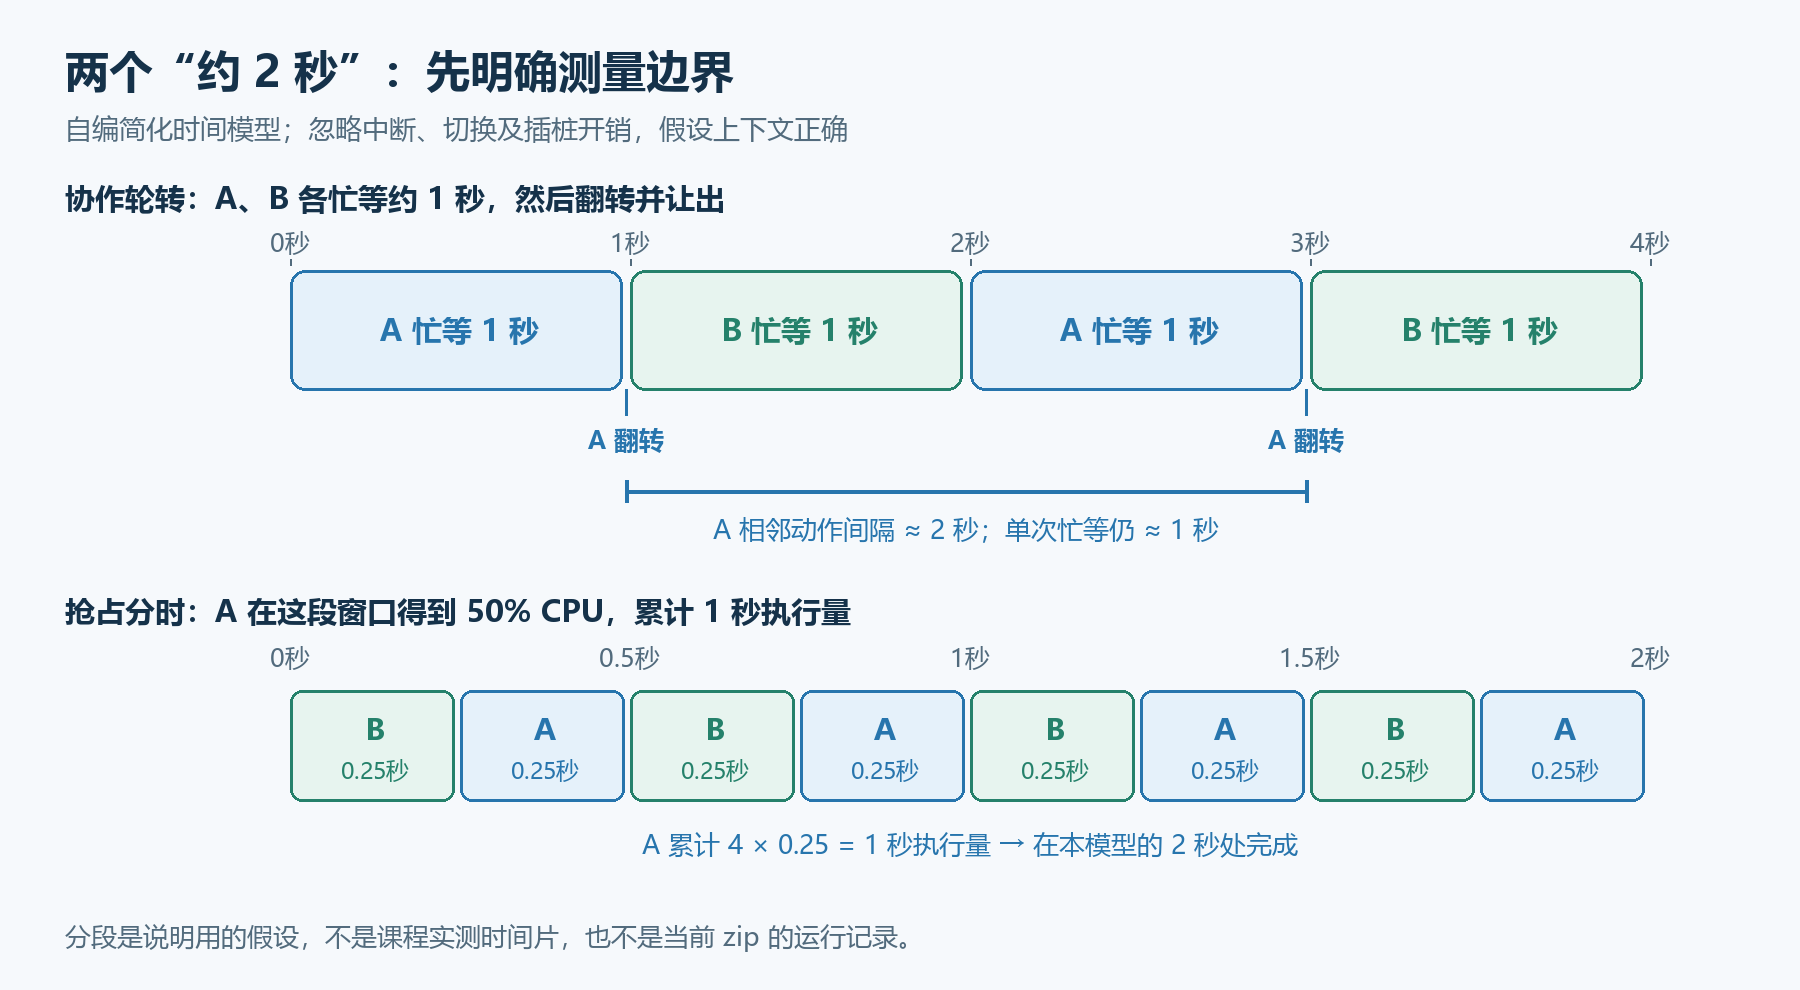

*自绘补充示意图。协作行显示相邻动作的间隔；抢占行使用0.25秒的简化分段，并在该窗口先安排B，使A累计1秒执行量在2秒处完成。分段仅用于计算演示，不是本课程实测时间片。*

这里延长的是从 Delay 入口到出口的时间，和上一节“每次调用仍约 1 秒、动作间隔变长”不同。

**与当前包的边界：**第 03 篇已核对，所读初始化代码没有开启定时器 1 中断 ET1；任务中的忙等待调用也已注释。因此，本节是抢占机制成立条件下的解释，不能认定当前 zip 已在执行这个分时延时过程。


## 13. “两秒”至少要区分四类原因

| 观察现象 | 可能原因 | 应测量或核对什么 |
|---|---|---|
| Delay 调用约1秒，任务动作却隔约2秒 | 协作任务之间加入了另一任务的运行 | Delay入口/出口及业务边沿分别测 |
| 一次 Delay 从入口到出口约2秒 | 正确分时下，CPU执行量需要更长真实时间 | 任务运行标记与累计执行时间 |
| 数值不固定，时长忽长忽短 | 计数寄存器、数据或返回帧被破坏 | 上下文、寄存器、局部数据与栈 |
| 每秒翻转一次，但同方向边沿隔2秒 | 波形一个周期需要两次翻转 | 相邻边沿和同方向边沿分别测 |

此外，时钟、定时器单位、驱动耗时或唤醒后的调度等待也可能影响时长。应先确定测的是哪一段，再对照代码排查。

视频标题提供了需要解释的现象，但未逐段观看的情况下，本篇不会替视频指定唯一的具体原因。表中的模型可帮助你根据实际程序与测量结果判断。


## 14. 每秒翻转一次，完整波形周期就是两秒

以下为**补充波形例子**。假设某输出在 0 秒为高电平，每隔 1 秒翻转一次：

```text
0—1秒：高
1—2秒：低
2—3秒：高
3—4秒：低
```

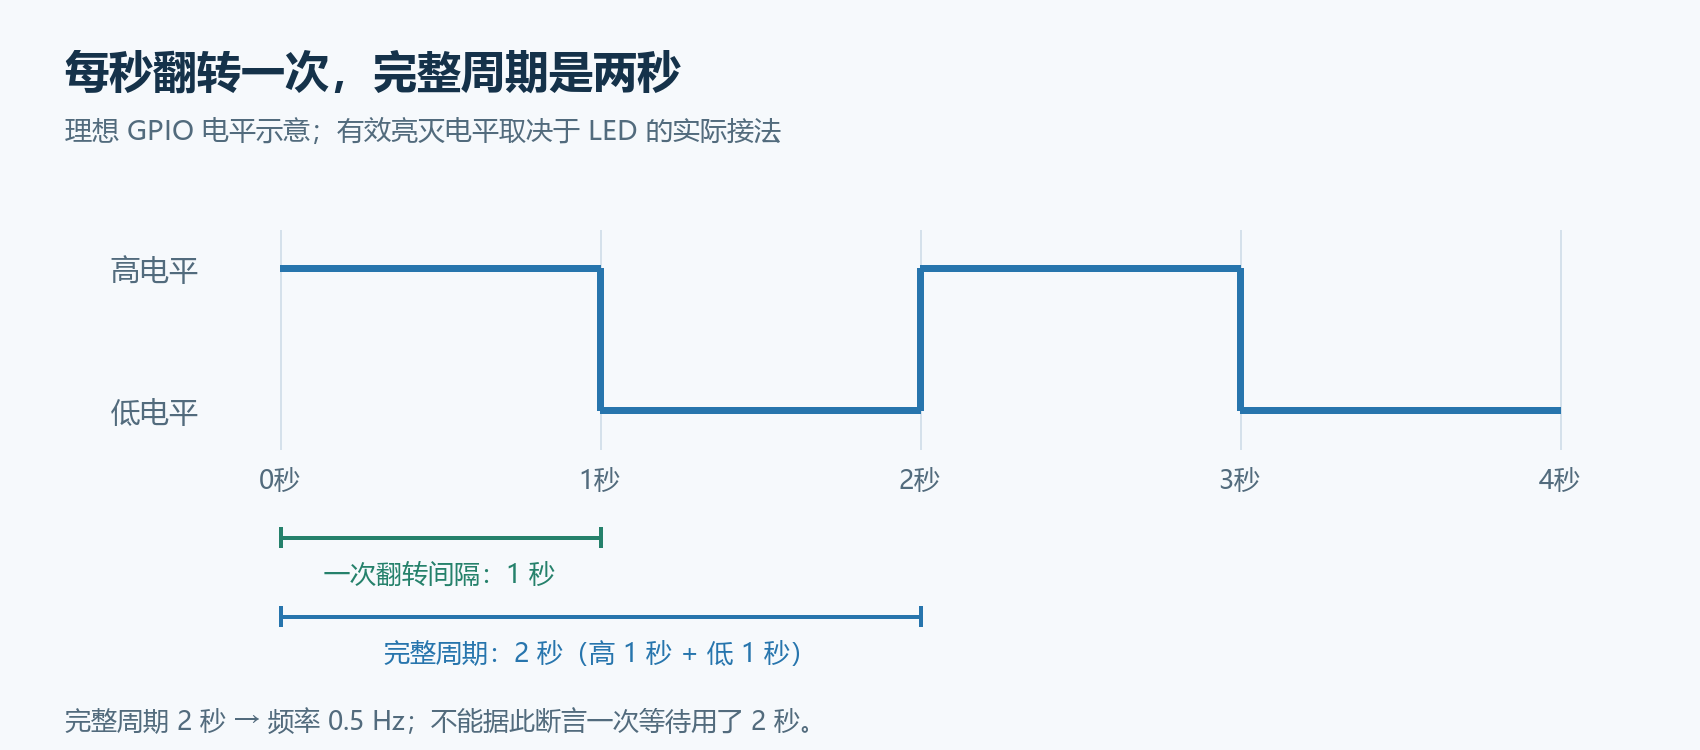

*自绘补充示意图，理想等间隔模型，不是硬件测量波形。*

| 测量对象 | 该模型中的时间 |
|---|---|
| 相邻一次上升/下降变化 | 1 秒 |
| 一段高电平或低电平 | 1 秒 |
| 相邻同方向边沿，例如上升到下一次上升 | 2 秒 |
| 完整周期对应的频率 | 0.5 Hz |

因此，看到仪器显示周期 2 秒，并不一定说明 `sleep(1000)` 等待了 2 秒。它可能只是正常的“高1秒、低1秒”。如果接了 LED，还应先确定有效电平，不能只凭亮灭观感判断程序执行路径。


## 15. 当前配套 sleep 会立刻停住函数吗？

配套 `main.c` 中的**实际实现**是：

```c
void sleep(unsigned int task_id , unsigned int delay_ms){
    tasks[task_id].status = TASK_SUSPENDED;
    tasks[task_id].delay_count = 0;
    tasks[task_id].delay_duration = delay_ms;
}
```

它设置状态与计数后立即返回，函数内没有 `task_switch`。因此，task0 当前的顺序是：

```text
检查本次是否挂起
→ sleep(0,1000) 设置挂起状态并返回
→ 本轮仍执行 P53 翻转
→ task_switch 让出
→ 下次回到循环，再检查挂起状态
```

不能仅看到函数名 `sleep` 就把它理解成桌面系统中“函数阻塞到超时后才返回”的 API。本例实际上靠调用之后的让出，以及下轮的状态检查，暂停后续业务。

如果把另一项重要操作直接写在 `sleep(...)` 之后、`task_switch()` 之前，它也可能在本轮立即执行。这个调用契约要在阅读任务代码时明确。

第 05 篇会详细解释定时器如何累计等待、改变状态，以及这种简化实现的同步与调度边界。


## 16. 忙等待、轮询和任务等待的区别

以下为**补充概念对照**。

| 方式 | 等待期间CPU做什么 | 对其他任务的影响 |
|---|---|---|
| 忙等待循环 | 不断执行计数或检查 | 消耗执行预算，协作模型中可能阻止别人运行 |
| 轮询后主动让出 | 检查条件，未满足则切换 | 别人可以运行，但检查本身仍有开销 |
| 内核阻塞等待 | 调度器不选择该等待任务 | 将CPU交给就绪任务，条件满足后再变就绪 |
| 硬件产生波形或计时事件 | 由外设维持相应时序，CPU按需处理 | 减少软件逐步等待，但仍需管理配置与事件 |

当前配套任务在挂起时仍被简单编号轮转选中，再由任务检查状态并让出，属于带让出的检查路径。它没有在 `task_switch` 中直接跳过所有挂起任务。

所以，使用状态变量和硬件计时已经有助于区分“等待时间”与“执行量”，但不代表示例已经具备成熟 RTOS 的就绪队列、空闲任务或标准阻塞接口。


## 17. 用真实时钟等待，为什么仍可能晚一点执行？

以下为**补充时间模型**，不是配套 `sleep` 的完整实现。

让硬件时间基准持续前进，任务记录开始时刻或到期时刻，超时后成为可运行状态。只要时钟基准正确推进，它无需通过累计一秒 CPU 指令来等一秒真实时间。

```text
请求等待 → 时钟推进 → 等待到期/变就绪 → 得到CPU → 执行业务
```

实际业务时刻还受以下部分影响：

| 部分 | 影响 |
|---|---|
| 时间单位与时钟精度 | 毫秒值是否对应正确真实时间 |
| tick量化与相位 | 请求发生在两个tick之间，边界可能有误差 |
| 中断响应和处理 | 超时检查可能被推迟 |
| 从就绪到运行的等待 | 其他任务、调度策略或临界区影响 |
| 业务操作耗时 | 最终GPIO翻转或驱动调用晚于任务开始运行 |

**等待到期不等于立刻执行。**这也解释了为什么用硬件计时后，仍应测量实际业务边沿，而不是只相信参数里的 `1000`。

长周期业务若采用“做完工作后再等1秒”，每轮会包含工作耗时；若要求按固定节拍，应考虑持续推进的到期基准和超期处理。这是补充设计方向，具体 tick、状态更新与计时计算放在第05篇。


## 18. 外设初始化与业务动作怎样安排？

以下为**补充整理方法**，没有修改原课程代码。

| 阶段 | 应明确的内容 | 对本例的提示 |
|---|---|---|
| 资源规划 | 引脚、外设实例、模式与复用归属 | P5.3、P2.7分别由哪个任务操作 |
| 初始化 | 初始输出、模式设置、依赖顺序 | 整端口清零可能影响其他引脚 |
| 任务业务 | 输出动作、等待条件、让出位置 | 当前sleep之后本轮仍会翻转 |
| 共享事务 | 保护边界与等待方式 | 串口/I²C等扩展例子需要整体协议 |
| 时间要求 | 动作间隔、周期、最晚响应 | 1秒翻转与2秒完整周期要区分 |

实际输出配置时，先写默认电平还是先切输出模式，需结合电路与芯片行为安排，以避免不期望的短暂输出。源码的课堂顺序不能替代具体设备的初始化要求。

如果两个任务后来复用同一个定时器或修改同一端口模式寄存器，也要回到资源规划层判断冲突。只保护任务寄存器，不会自动恢复每项任务想要的外设配置。


## 19. 用波形把几个时间分别量出来

以下为**补充调试方案，尚未在本环境执行**。逻辑分析仪或示波器观察GPIO，或用可靠硬件时钟记录时间，都能帮助区分模型。

可以在实际允许使用的空闲引脚安排标记：

- Delay入口置位、出口清零，脉冲宽度表示一次调用的真实持续时间。
- 业务动作使用原输出，观察相邻动作间隔。
- 任务运行或切换入口增加另一标记，估计CPU交错方式。

标记代码本身有开销，过多日志、串口打印或插桩会改变时序；测量时要知道它们增加了什么。

| 仪器读数 | 对应含义 | 常见误读 |
|---|---|---|
| Delay标记脉冲宽度 | 一次调用从入口到出口的真实时间 | 当成纯CPU执行时间 |
| 同一任务相邻业务边沿 | 两次动作间隔 | 当成某次Delay调用长度 |
| 相邻同方向边沿 | 完整波形周期 | 当成一次等待长度 |
| 任务标记的高电平累计时间 | 取决于插桩方式的运行时间近似 | 未排除ISR就认定全是任务指令 |

先查看实际调用是否启用，再选择测量点。当前源码中忙等待被注释、ET1未开启等事实，会决定哪些波形推演适用于这份包。


## 20. 验证顺序与故障定位

以下为**补充检查路线**，不是已完成的硬件测试报告。

1. 先核对引脚符号、模式与实际连线，确认两个任务控制的输出对应正确。
2. 单任务检查目标延时或等待单位，记录实际系统时钟与编译结果。
3. 在上下文正确的前提下加入第二个任务，分别量调用长度、动作间隔、完整周期。
4. 确认使用协作还是已启用的抢占调度，检查任务真正让出的位置。
5. 若结果不稳定，检查计数寄存器、共享数据、栈边界和中断返回路径。
6. 若外设输出互相覆盖，检查整端口配置、读改写和事务归属。

| 表现 | 优先排查 |
|---|---|
| 一个任务忙等时另一个无响应 | 是否纯协作、忙等中是否没有让出点 |
| 加任务后动作间隔稳定变长 | CPU分配、另一任务工作量与测量边界 |
| 周期2秒、每次电平持续1秒 | 是否只是正常翻转波形 |
| 延时忽长忽短、计数异常 | 上下文保护、函数重入、实际时钟与中断 |
| 修改一个引脚导致其他引脚异常 | 整端口写、模式配置、复用或资源重叠 |
| 配置了计数器但没有周期抢占 | 对应中断允许位、向量、返回协议 |
| UART消息交错、I²C事务错误 | 事务边界是否有统一管理 |

一次观察不能覆盖所有切换点。第03篇介绍的寄存器与返回帧检查仍是本篇时间分析成立的前提。


## 21. 一页复习表

| 知识点 | 应能说明 |
|---|---|
| 本例输出 | task0翻转P5.3，task1翻转P2.7 |
| 端口模式 | 清M0/M1整字节会影响整个端口的相应配置 |
| 位翻转机器码 | 本次使用CPL bit，不能臆测为多条读改写 |
| 任务与外设 | 私有栈不等于私有GPIO或私有UART |
| 多步共享操作 | 保护边界由实际指令与协议决定 |
| 外设事务 | 可能需要保护整条消息或START到STOP过程 |
| 忙等待 | 累计执行指令，不是按真实时钟直接阻塞任务 |
| 协作模型 | Delay每次仍约1秒，另一任务可能拉长动作间隔 |
| 抢占模型 | 固定执行量在较低CPU份额下耗费更长真实时间 |
| 上下文错误 | 会破坏计数，不能简单归为固定倍数变慢 |
| 翻转与周期 | 1秒翻转一次对应理想完整周期2秒 |
| 当前源码 | Delay调用已注释，sleep设置状态后立即返回 |
| 等待与恢复 | 到期、变就绪、得到CPU、执行业务是不同阶段 |
| 验证方法 | 分别量调用持续时间、动作间隔和同方向边沿周期 |


## 22. 自测与参考答案

1. task0和task1在配套循环中分别翻转哪两个引脚？
2. `P5M0=0`、`P5M1=0`是否只修改P5.3的模式？
3. 本次`P53=~P53`生成什么指令？能否断言它是可被中断拆开的多步软件读改写？
4. 两项任务各有私有栈，是否就各有一份UART？
5. UART每个字符都安全发送，是否就保证两条消息不会交错？
6. `Delay1000ms`内部是否调用了`task_switch`或读取系统毫秒数？
7. 协作模型中A、B各忙等1秒后翻转并让出，A相邻翻转约隔多久？A每次Delay调用是否一定变成2秒？
8. 需要1秒CPU执行量的循环，平均只得到50%CPU时，真实时间可粗略估计为多少？
9. 每隔1秒翻转一次引脚，完整周期和频率各是多少？
10. 计数寄存器被另一个任务改掉后，能否仍用“固定执行量/CPU份额”解释延时？
11. 当前配套`sleep`返回后，紧接着的GPIO翻转是否会先等待1000ms再执行？
12. 想知道一次Delay调用真实持续多久，应该测业务完整周期还是入口/出口标记？
13. `volatile`是否能保证外设事务不交错、或恢复循环寄存器？
14. 包内有`Timer1_ISR`和`TR1=1`，是否就证明定时器1抢占已启用？

### 参考答案

1. P5.3与P2.7。
2. 不是。这里写的是整字节模式寄存器。
3. `CPL 0CBH`。本次是单条位指令，不能按C表达式猜成多条。
4. 没有。外设实例通常仍是芯片共享硬件。
5. 不能。消息完整性需要明确整条消息的访问边界。
6. 都没有，它是执行计数循环的忙等待。
7. 相邻翻转约2秒；每次调用在该无抢占模型中仍约1秒，动作间隔包含另一个任务的运行。
8. 约2秒，前提是工作量与平均份额成立，并忽略其他开销。
9. 理想周期2秒，频率0.5Hz。
10. 不能直接套用，计数被破坏后工作量已经可能变化。
11. 不会由sleep函数直接阻塞。它设置状态并返回，本轮接着翻转，然后显式让出。
12. 入口/出口标记；业务周期是另一个测量对象。
13. 都不能。它不提供事务互斥或上下文保存。
14. 不能。所读初始化没有开启ET1，计数运行不等于中断允许。

### 自编计算练习

A每轮忙等0.2秒，B每轮忙等0.8秒，各自完成后翻转并主动让出。假设没有抢占、其他开销可忽略，A首次从0秒开始：A前三次翻转在什么时刻？A相邻翻转和完整理想周期分别是多少？

**答案：**A分别在0.2、1.2、2.2秒翻转；相邻翻转间隔1秒，完整周期2秒。A的一次忙等待仍只需0.2秒，间隔中还包含B的0.8秒。这说明周期不能直接由某一任务的延时参数推断。


## 23. 来源、五篇规划与下一篇

资料来源：[《自己动手写嵌入式操作系统》课程网盘](https://pan.baidu.com/s/1BaPETt4F3Xnew179lHT4DA?pwd=9988)，提取码 `9988`。

| 本篇内容 | 依据与边界 |
|---|---|
| 视频16—17的主题 | 已核对课程目录标题 |
| 引脚初始化、翻转、注释的Delay调用、sleep顺序 | `os_demo/main.c` |
| 位符号、函数地址、循环变量位置 | `Listings/project.m51` |
| GPIO位指令与Delay循环指令 | `Objects/project.hex`的对应字节与记录校验和 |
| 工程与编译配置 | `project.uvproj`、`Listings/main.lst` |
| 外设共享、读改写、串口/I²C、时间模型和测量方法 | 补充原理与自编例子，未作为课程实测结果 |
| 两张时间示意图 | 自绘补充示意，非硬件采集波形 |

| 编号 | 笔记 | 对应视频 |
|---|---|---|
| 01 | [操作系统基础、多任务与资源调度](01-操作系统基础、多任务与资源调度.ipynb) | 01—08 |
| 02 | [STC内存、任务堆栈与任务切换原理](02-STC内存、任务堆栈与任务切换原理.ipynb) | 09—13 |
| 03 | [任务调度器与上下文保护](03-任务调度器与上下文保护.ipynb) | 14—15 |
| 04 | 多任务外设访问与延时问题 | 16—17 |
| 05 | sleep实现与定时时间片轮转 | 18—19 |

下一篇展开：用任务状态和硬件计时实现等待，定时器如何累计计数与唤醒任务，如何区分计时tick和调度时间片，以及当前配套初始化、共享计数和中断切换还需要检查哪些条件。
